# Searching Over Features

> **Overview.** 03 with search: every so often the LTUs with the smallest output weights are replaced by LTUs reading
> newly sampled inputs.

The step after `03_several_targets.ipynb`. There, LTUs whose inputs are sampled once, by the linear learner's weights,
get past the linear solution with one target LTU but not with four or eight: a sampled LTU reads only about $1/K$ of
its inputs from any one target LTU, so few of the 32 samples are good enough to learn. Here the LTUs search: every so
often, the LTUs that contribute least are replaced by newly sampled ones. Does search recover what sampling once loses
as $K$ grows, and how does that depend on how often LTUs are replaced?

**Problem.** As in `03_several_targets.ipynb`: $N = 1000$ standard normal inputs, and the target is
$\frac{1}{\sqrt{K}} \sum_{k=1}^{K} \mathrm{sign}(w_k \cdot x_k)$ plus $N(0, 0.1^2)$ noise, where target LTU $k$ reads
$x_k$, the $k$-th block of 10 inputs, with random $\pm 1$ weights $w_k$. The best possible RMSE is 0.1 (dotted line),
and the best linear learner's about 0.61 for every $K$ (dashed line). Each seed has its own target weights; a run with
$K$ target LTUs uses the first $K$ of the seed's 8.

**Learner.** As in `03_several_targets.ipynb`: one output reading every input directly (the *linear learner*), a bias,
and 32 hidden LTUs (sigmoid derivative backward) with fixed shadow output weights, +1 and -1 alternately, which stand
in for the real weights in the backward pass while the real ones are smaller in magnitude. Network Autostep, online, on
half the squared error (`squared_inputs`, initial step-size $10^{-4}$, meta step-size 0.02, $\tau = 10^4$), with the
hidden units standardized online. The linear learner learns alone for the first 100k steps; then the LTUs are added,
each reading 1 to 20 inputs (its fan-in uniform) drawn without replacement with probability proportional to the square
of the linear learner's weight on each, its input weights starting LeCun uniform over its fan-in; then everything
learns for 1M more steps.

**Search.** Every $P$ steps after the LTUs are added, the 4 LTUs with the smallest output weight magnitude are
replaced. Each gets newly sampled inputs, drawn as when the LTUs were added but from the linear learner's current
weights, fresh LeCun uniform input weights, an output weight of 0, and fresh statistics and Autostep state (every
step-size back to the initial one); it keeps its shadow weight.

**Runs.** $K$ = 1, 2, 4 and 8 target LTUs, 5 seeds each; the same seed gives every run the same samples and target
weights. *Search* (proposed): $P$ = 10k, 30k and 100k steps. *No search* (baseline): the sampled LTUs are never
replaced, as in `03_several_targets.ipynb`. *LTUs reading one target LTU's inputs* (reference): each pair of LTUs reads
one target LTU's 10 inputs, its input weights starting $U(-\sqrt{3/10}, \sqrt{3/10})$, without search. *Linear
learner* (baseline): no LTUs. Curves are the mean over seeds of the RMSE averaged over windows of 1k steps; final
performance is the RMSE over the last 10% of steps.

In [1]:
import os
from time import perf_counter
from typing import NamedTuple

os.environ['XLA_PYTHON_CLIENT_PREALLOCATE'] = 'false'   # take GPU memory only as needed, so the GPU can be shared
import jax
jax.config.update('jax_platforms', 'cuda')
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np

from phd.jax_core.models import ltu
from phd.jax_core.optimizers.idbd import IDBDState, optax_idbd

%matplotlib inline
assert jax.default_backend() == 'gpu'

/home/edan/miniconda3/envs/jax/lib/python3.10/site-packages/pydantic/_internal/_generate_schema.py:2274: UnsupportedFieldAttributeWarning: The 'repr' attribute with value False was provided to the `Field()` function, which has no effect in the context it was used. 'repr' is field-specific metadata, and can only be attached to a model field using `Annotated` metadata or by assignment. This may have happened because an `Annotated` type alias using the `type` statement was used, or if the `Field()` function was attached to a single member of a union type.
  warnings.warn(
/home/edan/miniconda3/envs/jax/lib/python3.10/site-packages/pydantic/_internal/_generate_schema.py:2274: UnsupportedFieldAttributeWarning: The 'frozen' attribute with value True was provided to the `Field()` function, which has no effect in the context it was used. 'frozen' is field-specific metadata, and can only be attached to a model field using `Annotated` metadata or by assignment. This may have happened because an 

In [2]:
# --- Problem ---
N_INPUTS = 1000
N_SOURCES = 10                       # each target LTU reads its own block of N_SOURCES inputs, from the first
NOISE_STD = 0.1                      # observation noise on the target: the RMSE floor
LINEAR_RMSE = np.sqrt(1 - 2 / np.pi + NOISE_STD ** 2)   # the best linear learner's RMSE

# --- Learner ---
STAT_RATE, VAR_FLOOR = 1e-3, 0.01    # standardization of the hidden units
INIT_STEP_SIZE = 1e-4                # Autostep's initial step-size
META_STEP_SIZE, TAU = 0.02, 1e4
N_LTUS = 32                          # hidden LTUs
MAX_FAN_IN = 20                      # LTUs with sampled inputs read 1 to MAX_FAN_IN of them
REPLACED = 4                         # LTUs replaced at each search step, those with the smallest |output weight|

# --- Experiment ---
LINEAR_STEPS = 100_000               # the linear learner learns alone for this many steps, then the LTUs are added
NUM_STEPS = 1_000_000                # steps after the LTUs are added
WINDOW = 1_000                       # steps per recorded RMSE
N_SEEDS = 5
TARGET_COUNTS = (1, 2, 4, 8)         # target LTUs
PERIODS = (2_000, 5_000, 10_000, 30_000, 100_000)  # steps between search steps

## Learner

In [3]:
OPTIMIZER = optax_idbd(meta_lr=META_STEP_SIZE, init_lr=INIT_STEP_SIZE, autostep=True, tau=TAU,
                       version='squared_inputs')


@jax.custom_vjp
def standardize(bits, mean, error_mean, error_h_mean):
    return (bits - mean) / jnp.sqrt(jnp.maximum(mean * (1 - mean), VAR_FLOOR))


def standardize_fwd(bits, mean, error_mean, error_h_mean):
    variance = mean * (1 - mean)
    scale = jnp.sqrt(jnp.maximum(variance, VAR_FLOOR))
    h = (bits - mean) / scale
    return h, (h, scale, variance > VAR_FLOOR, error_mean, error_h_mean)


def standardize_bwd(saved, g):
    h, scale, unfloored, error_mean, error_h_mean = saved
    return (g - error_mean - jnp.where(unfloored, h * error_h_mean, 0.)) / scale, None, None, None


standardize.defvjp(standardize_fwd, standardize_bwd)


class Stats(NamedTuple):
    # Running statistics of the hidden units, each shaped (units,).
    hidden_mean: jax.Array      # firing rate
    error_mean: jax.Array       # means of the error g arriving at each hidden unit, and of g * h
    error_h_mean: jax.Array


class Net(NamedTuple):
    # w['hidden'] is the hidden units' weights over [inputs, 1 (the bias)], of which they read those in `reads`;
    # w['output'] is the output's weights over [inputs (the linear learner), the hidden units, 1]. `mask` says which of
    # the output's connections exist; the hidden units' are switched on when the units are added.
    w: dict                     # {'hidden': (slots, N_INPUTS + 1), 'output': (1, N_INPUTS + slots + 1)}
    reads: jax.Array            # (slots, N_INPUTS + 1)
    mask: jax.Array             # shaped like w['output']
    opt: IDBDState
    stats: Stats
    shadow: jax.Array           # (slots,): each hidden unit's shadow output weight, +-1, or 0 for an empty slot


def init_net(key, units, slots, targets):
    # `units` hidden units in `slots` slots, the rest left empty, each pair reading the inputs of one of the `targets`
    # target LTUs in turn and the bias; their shadow weights +1 and -1 alternately, their input weights LeCun uniform,
    # U(-sqrt(3 / N_SOURCES), sqrt(3 / N_SOURCES)); every other weight at 0.
    target = jnp.arange(slots) // 2 % targets
    reads = jnp.append(jnp.arange(N_INPUTS) // N_SOURCES == target[:, None], jnp.ones((slots, 1), bool), axis=1)
    shadow = jnp.where(jnp.arange(slots) < units, jnp.where(jnp.arange(slots) % 2 == 0, 1.0, -1.0), 0.0)
    mask = jnp.concatenate([jnp.ones(N_INPUTS, bool), jnp.zeros(slots, bool), jnp.ones(1, bool)])[None]
    w = {'hidden': (jax.random.uniform(key, (slots, N_INPUTS + 1), minval=-1.0, maxval=1.0)
                    * jnp.sqrt(3.0 / N_SOURCES) * reads).at[:, -1].set(0.0),
         'output': jnp.zeros((1, N_INPUTS + slots + 1))}
    stats = Stats(jnp.full(slots, 0.5), jnp.zeros(slots), jnp.zeros(slots))
    return Net(w, reads, mask, OPTIMIZER.init(w), stats, shadow)


def rewire(net, key, replaced):
    # The `replaced` hidden units (a mask over slots) each read 1 to MAX_FAN_IN inputs (uniform) and the bias, the
    # inputs drawn without replacement with probability proportional to the square of the linear learner's weight on
    # them (Gumbel top-k), with fresh LeCun uniform input weights over their fan-in, output weights at 0, and fresh
    # statistics and Autostep state.
    slots = len(net.shadow)
    fan_key, draw_key, w_key = jax.random.split(key, 3)
    fan_in = jax.random.randint(fan_key, (slots, 1), 1, MAX_FAN_IN + 1)
    scores = jnp.log(net.w['output'][0, :N_INPUTS] ** 2) + jax.random.gumbel(draw_key, (slots, N_INPUTS))
    reads = jnp.append(jnp.argsort(jnp.argsort(-scores)) < fan_in, jnp.ones((slots, 1), bool), axis=1)
    hidden = jax.random.uniform(w_key, reads.shape, minval=-1.0, maxval=1.0) * jnp.sqrt(3.0 / fan_in) * reads
    where = {'hidden': replaced[:, None],
             'output': jnp.concatenate([jnp.zeros(N_INPUTS, bool), replaced, jnp.zeros(1, bool)])[None]}
    reset = lambda tree, fresh: jax.tree.map(lambda m, a, b: jnp.where(m, a, b), where, fresh, tree)
    w = reset(net.w, {'hidden': hidden.at[:, -1].set(0.0), 'output': jnp.zeros_like(net.w['output'])})
    zeros = jax.tree.map(jnp.zeros_like, net.w)
    opt = net.opt._replace(beta=reset(net.opt.beta, jax.tree.map(lambda a: a + net.opt.init_beta, zeros)),
                           h=reset(net.opt.h, zeros), v=reset(net.opt.v, zeros))
    stats = Stats(*(jnp.where(replaced, fresh, old) for fresh, old in zip((0.5, 0.0, 0.0), net.stats)))
    return net._replace(w=w, reads=jnp.where(replaced[:, None], reads, net.reads), opt=opt, stats=stats)


def learn(net, x, y):
    # One online network-Autostep update on half the squared error, each shadow weight standing in for its hidden
    # unit's output weight in the backward pass while the real one is smaller in magnitude. Returns the new network and
    # the squared error on this sample, before learning from it. `probe` is zero; its gradient is the error arriving at
    # each hidden unit.
    units = len(net.shadow)

    def loss_fn(w, probe):
        w = {'hidden': w['hidden'] * net.reads, 'output': w['output'] * net.mask}
        b = ltu(w['hidden'] @ jnp.append(x, 1.0))
        mean = net.stats.hidden_mean + STAT_RATE * (jax.lax.stop_gradient(b) - net.stats.hidden_mean)
        h = standardize(b, mean, net.stats.error_mean, net.stats.error_h_mean)
        a = h + probe
        source = jnp.concatenate([x, a, jnp.ones(1)])
        unit_w = w['output'][0, N_INPUTS:N_INPUTS + units]
        through_back = jnp.sum(jnp.where(jnp.abs(unit_w) < 1.0, net.shadow, unit_w) * net.mask[0, N_INPUTS:-1] * a)
        prediction = (w['output'] @ jax.lax.stop_gradient(source) + through_back
                      - jax.lax.stop_gradient(through_back))
        sources = {'hidden': jnp.append(x, 1.0) * net.reads,
                   'output': jax.lax.stop_gradient(source)[None] * net.mask}
        return 0.5 * jnp.sum((prediction - y) ** 2), (sources, jax.lax.stop_gradient(h), mean)

    (loss, (sources, h, mean)), (grads, error) = jax.value_and_grad(loss_fn, (0, 1), has_aux=True)(net.w, jnp.zeros(units))
    grads = {'hidden': grads['hidden'] * net.reads, 'output': grads['output'] * net.mask}
    updates, opt = OPTIMIZER.update((grads, None, sources), net.opt, net.w)
    stats = Stats(mean, net.stats.error_mean + STAT_RATE * (error - net.stats.error_mean),
                  net.stats.error_h_mean + STAT_RATE * (error * h - net.stats.error_h_mean))
    return net._replace(w=jax.tree.map(jnp.add, net.w, updates), opt=opt, stats=stats), 2 * loss

## Training

In [4]:
def train(net, key, targets, sampled, period, add_step, num_steps):
    # num_steps online network-Autostep steps on targets from this seed's first `targets` target LTUs, the hidden units
    # added at add_step (first rewired if sampled), and every `period` steps after that (never if period is 0) the
    # REPLACED of them with the smallest |output weight| rewired. Returns each window's mean squared error.
    target_key, key = jax.random.split(key)
    wire_key = jax.random.fold_in(target_key, 1)
    target_w = jax.random.rademacher(target_key, (max(TARGET_COUNTS), N_SOURCES), dtype=float)
    used = jnp.arange(max(TARGET_COUNTS)) < targets

    def one_step(net, inputs):
        step, key = inputs
        x_key, noise_key = jax.random.split(key)
        x = jax.random.normal(x_key, (N_INPUTS,))
        blocks = x[:target_w.size].reshape(target_w.shape)
        y = (jnp.sum(jnp.where(jnp.sum(target_w * blocks, 1) > 0, 1.0, -1.0) * used) / jnp.sqrt(targets)
             + NOISE_STD * jax.random.normal(noise_key, (1,)))
        net = net._replace(mask=net.mask.at[0, N_INPUTS:-1].set((step >= add_step) & (net.shadow != 0)))
        return learn(net, x, y)

    def window(net, inputs):
        index, key = inputs
        net, mse = jax.lax.scan(one_step, net, (index * WINDOW + jnp.arange(WINDOW), jax.random.split(key, WINDOW)))
        since_added = (index + 1) * WINDOW - add_step
        due = (period > 0) & (since_added > 0) & (since_added % jnp.maximum(period, 1) == 0)
        weakest = jnp.argsort(jnp.where(net.shadow != 0, jnp.abs(net.w['output'][0, N_INPUTS:-1]), jnp.inf))[:REPLACED]
        searched = rewire(net, jax.random.fold_in(wire_key, index), jnp.zeros(len(net.shadow), bool).at[weakest].set(True))
        return jax.tree.map(lambda a, b: jnp.where(due, a, b), searched, net), mse.mean()

    n, added = num_steps // WINDOW, add_step // WINDOW
    index, keys = jnp.arange(n), jax.random.split(key, n)
    net, before = jax.lax.scan(window, net, (index[:added], keys[:added]))
    net = jax.tree.map(lambda a, b: jnp.where(sampled, a, b), rewire(net, wire_key, net.shadow != 0), net)
    return jnp.concatenate([before, jax.lax.scan(window, net, (index[added:], keys[added:]))[1]])


def run(configs):
    # Each (units, targets, sampled, period) of configs: `units` hidden LTUs reading sampled inputs if sampled, searched
    # every `period` steps (0: never), and one target LTU's inputs otherwise (no LTUs: the linear learner alone), on
    # `targets` target LTUs, each on N_SEEDS seeds, vmapped together. Seed s gives every run the same samples and target weights. Returns {config: the RMSE of each
    # window from step 1, shaped (seed, window)}.
    units, targets, sampled, period, seed = (jnp.array(v) for v in zip(*[(*c, s) for c in configs
                                                                          for s in range(N_SEEDS)]))
    slots = max(max(c[0] for c in configs), 1)
    keys = lambda k: jax.random.split(jax.random.PRNGKey(k), N_SEEDS)[seed]
    nets = jax.vmap(lambda k, u, t: init_net(k, u, slots, t))(keys(0), units, targets)
    train_all = jax.jit(jax.vmap(lambda n, k, t, s, p: train(n, k, t, s, p, LINEAR_STEPS, LINEAR_STEPS + NUM_STEPS)))
    mse = train_all(nets, keys(1), targets, sampled, period)
    return dict(zip(configs, np.sqrt(np.asarray(mse)).reshape(len(configs), N_SEEDS, -1)))

## Runs

In [5]:
started = perf_counter()
linear = run([(0, k, False, 0) for k in TARGET_COUNTS])
ltus = run([(N_LTUS, k, sampled, period) for k in TARGET_COUNTS
            for sampled, period in [(False, 0), (True, 0)] + [(True, p) for p in PERIODS]])
print(f'{(len(linear) + len(ltus)) * N_SEEDS} runs in {perf_counter() - started:.0f}s')
linear = {k: linear[(0, k, False, 0)] for k in TARGET_COUNTS}
reference = {k: ltus[(N_LTUS, k, False, 0)] for k in TARGET_COUNTS}
search = {p: {k: ltus[(N_LTUS, k, True, p)] for k in TARGET_COUNTS} for p in PERIODS}
no_search = {k: ltus[(N_LTUS, k, True, 0)] for k in TARGET_COUNTS}

160 runs in 466s


In [17]:
def cos_sim(a, b):
    return jnp.dot(a, b) / (jnp.linalg.norm(a) * jnp.linalg.norm(b))


a = np.array([1.0] + [-1] * 9)
b = np.array([1.0] + [0] * 9)

cos_sim(a, b)

Array(0.31622776, dtype=float32)

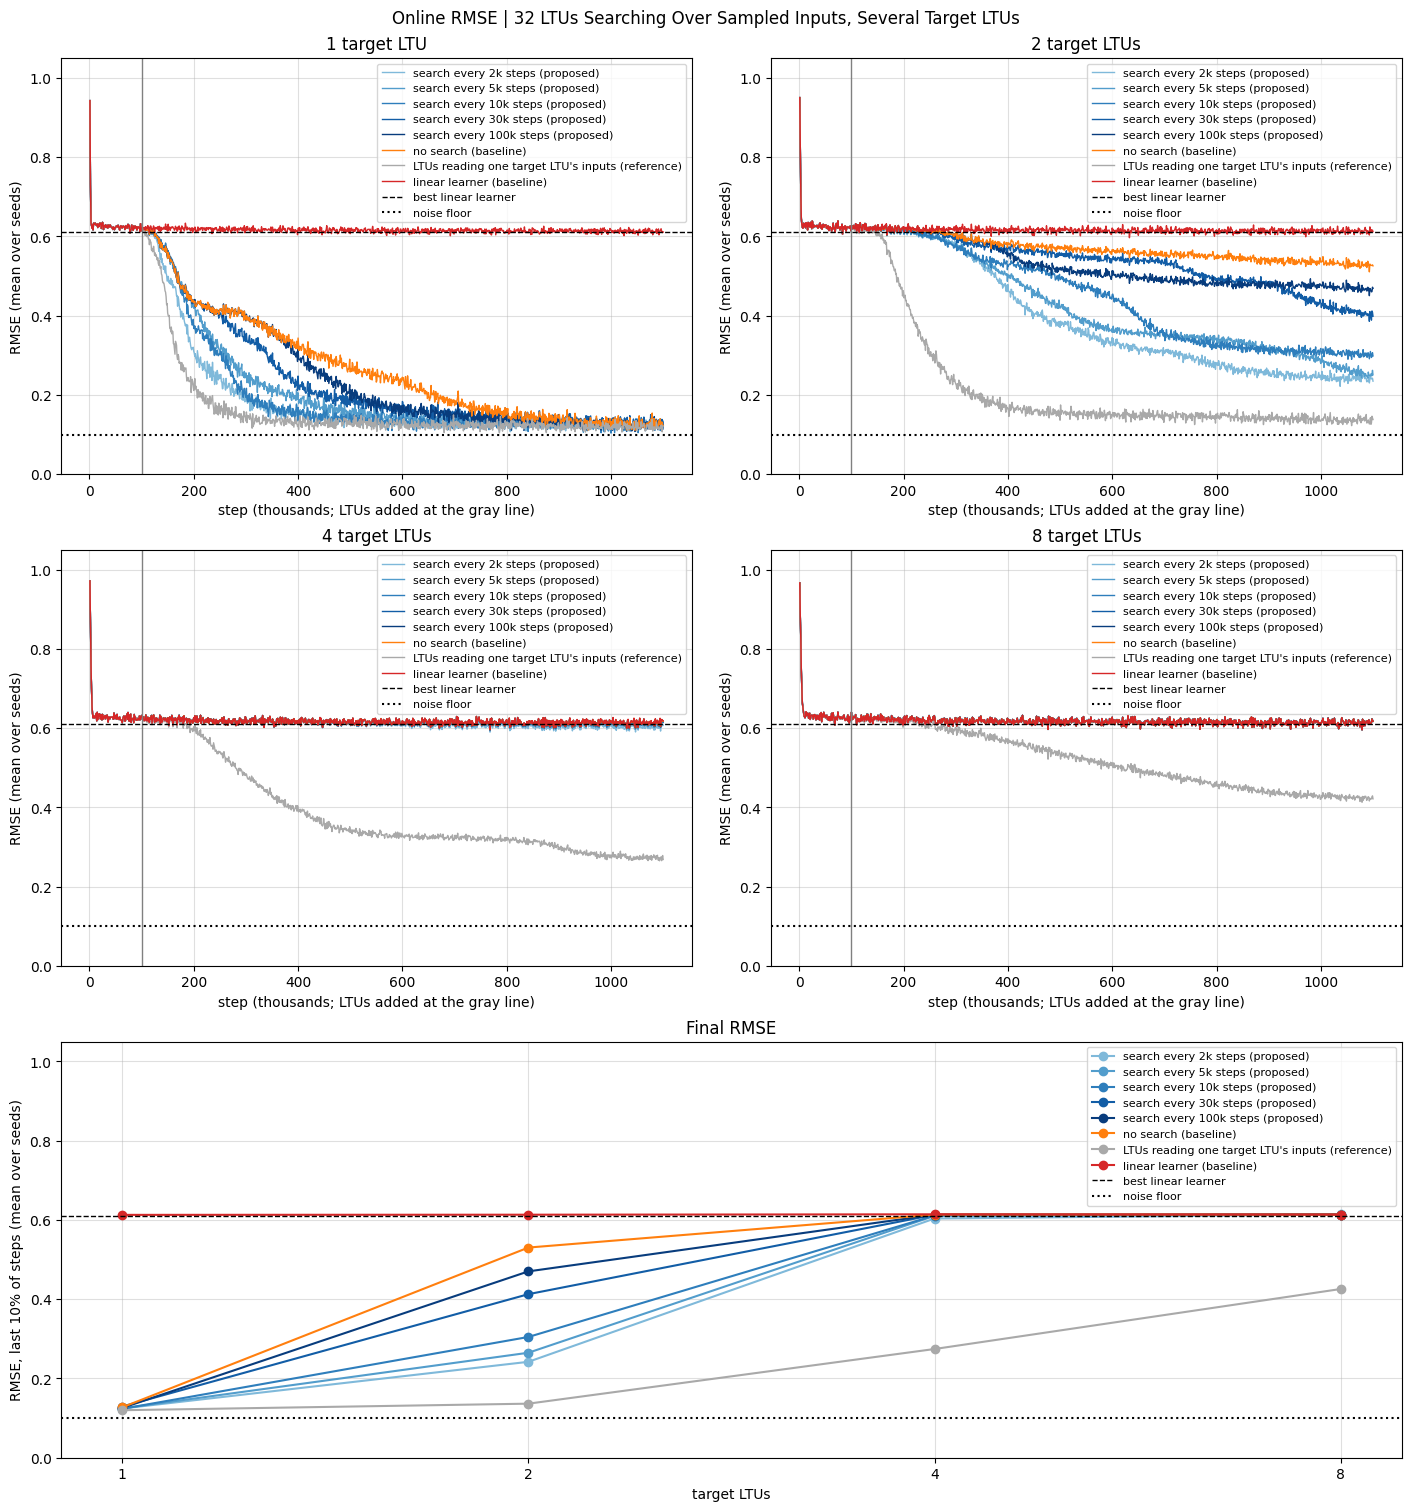

In [6]:
STEPS = (np.arange((LINEAR_STEPS + NUM_STEPS) // WINDOW) + 1) * WINDOW
METHODS = {**{f'search every {p // 1000}k steps (proposed)': (search[p], color)
              for p, color in zip(PERIODS, plt.cm.Blues(np.linspace(0.45, 0.95, len(PERIODS))))},
           'no search (baseline)': (no_search, 'tab:orange'),
           "LTUs reading one target LTU's inputs (reference)": (reference, 'darkgray'),
           'linear learner (baseline)': (linear, 'tab:red')}
final = lambda rmse: rmse[:, -(NUM_STEPS // WINDOW // 10):].mean(1)   # each seed's RMSE over the last 10% of steps

fig, axes = plt.subplot_mosaic([[1, 2], [4, 8], ['final', 'final']], figsize=(14, 15), layout='constrained')
for k in TARGET_COUNTS:
    ax = axes[k]
    for label, (runs, color) in METHODS.items():
        ax.plot(STEPS / 1000, runs[k].mean(0), color=color, lw=1, label=label)
    ax.axvline(LINEAR_STEPS / 1000, color='gray', lw=1)
    ax.set(xlabel='step (thousands; LTUs added at the gray line)', ylabel='RMSE (mean over seeds)', ylim=(0, 1.05),
           title=f'{k} target LTU{"s" if k > 1 else ""}')

ax = axes['final']
for label, (runs, color) in METHODS.items():
    ax.plot(TARGET_COUNTS, [final(runs[k]).mean() for k in TARGET_COUNTS], 'o-', color=color, label=label)
ax.set_xscale('log', base=2)
ax.set_xticks(TARGET_COUNTS, [str(n) for n in TARGET_COUNTS])
ax.set(xlabel='target LTUs', ylabel='RMSE, last 10% of steps (mean over seeds)', ylim=(0, 1.05), title='Final RMSE')
for ax in axes.values():
    ax.axhline(LINEAR_RMSE, color='black', ls='--', lw=1, label='best linear learner')
    ax.axhline(NOISE_STD, color='black', ls=':', label='noise floor')
    ax.grid(alpha=0.4)
    ax.legend(fontsize=8)
fig.suptitle(f'Online RMSE | {N_LTUS} LTUs Searching Over Sampled Inputs, Several Target LTUs')
plt.show()

## Results

5 seeds per configuration; final performance is the RMSE over the last 10% of steps. The notebook takes about 3.5
minutes.

- **Search helps with 1 and 2 target LTUs, more the more often it replaces LTUs.** With 2 target LTUs the final RMSE is
  0.30 searching every 10k steps, 0.41 every 30k and 0.47 every 100k, against 0.53 without search; the reference
  reaches 0.13. With 1, every method ends at 0.12 to 0.13, and searching every 10k steps gets there soonest.
- **With 4 and 8 target LTUs search does nothing**: every run with sampled inputs stays at the linear learner's 0.61, at
  every period, while the reference reaches 0.27 and 0.42.